# Bouma (1970) with a vision-language model

Every trial of Bouma's experiment, asked to Qwen3-VL-2B-Instruct. The displays are drawn by
`stimuli.py` (in this folder), which has all the numbers: Bouma's letter size and spacing,
eccentricities 2, 3, 5 and 7 deg, gaps of 0-15 empty letter slots plus the letter alone,
25 letters x 4 = 100 trials per condition.

Two things vary:

- **resolution:** Bouma had paper, not pixels, so we draw his sheet at three resolutions (about 32, 52 and 103 pixels per degree).
- **flankers:** Bouma's "x" on both sides, and random letters (the usual modern design).

Results go to `../data/model_results.csv`, one row per trial. The analysis (fits, figures) runs
on the computer from that file, with the same code as for Bouma's data.

Needs a GPU: in Colab, Runtime > Change runtime type > T4 GPU.

## Setup

In [1]:
import os
import sys

inColab = "google.colab" in sys.modules

if inColab:
  from google.colab import drive
  drive.mount("/content/drive")
  os.chdir("/content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code")
  os.system("pip install -q -U transformers")

sys.path.insert(0, os.getcwd())
print("running in Colab:", inColab)
print("folder:", os.getcwd())

Mounted at /content/drive
running in Colab: True
folder: /content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code


In [2]:
import time
import torch
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
from transformers       import AutoModelForImageTextToText, AutoProcessor
from transformers.utils import logging

import stimuli

logging.disable_progress_bar()
logging.set_verbosity_error()

if torch.cuda.is_available():
  device = "cuda"
  dtype  = torch.float16
else:
  device = "cpu"
  dtype  = torch.float32

print("device:", device)

device: cuda


In [3]:
modelName = "Qwen/Qwen3-VL-2B-Instruct"

model = AutoModelForImageTextToText.from_pretrained(modelName, dtype=dtype)
model = model.to(device)
model = model.eval()
proc  = AutoProcessor.from_pretrained(modelName)


def makeInputs(img, question):
  messages = [
    {"role": "user",
     "content": [
       {"type": "image", "image": img},
       {"type": "text",  "text":  question},
     ]}
  ]
  inputs = proc.apply_chat_template(messages,
                                    tokenize=True,
                                    add_generation_prompt=True,
                                    return_dict=True,
                                    return_tensors="pt")
  inputs = inputs.to(device)
  inputs["pixel_values"] = inputs["pixel_values"].to(dtype)
  return inputs


def nextWordScores(img, question):
  # one forward pass: a score for every word the model could say first
  inputs = makeInputs(img, question)
  with torch.no_grad():
    output = model(**inputs, logits_to_keep=1)
  return output.logits[0, -1].float().cpu()

print("model loaded")

model loaded


## The question and the scoring

One question for every display, with one letter or three, on either side of the cross:

> Look at the letters on one side of the cross. If there are three letters in a row, name the
> middle one. If there is only one letter, name it. Answer with a single lowercase letter.

The answer is the most likely of the 25 letters (a-z without x), so guessing gives 1/25 = 4%
correct, as for Bouma's observers. Bouma's observers could also say "illegible"; the model
can't.

In [4]:
question = ("Look at the letters on one side of the cross. If there are three letters in a row, "
            "name the middle one. If there is only one letter, name it. "
            "Answer with a single lowercase letter.")
letters  = stimuli.LETTERS

# token IDs of " a", " b", ... (with the leading space, as in notebook 01); each must be one token
letterIds = []
for L in letters:
  ids = proc.tokenizer.encode(" " + L, add_special_tokens=False)
  assert len(ids) == 1, L
  letterIds.append(ids[0])


def letterProbs(img):
  scores = nextWordScores(img, question)
  return torch.softmax(scores[letterIds], dim=0).numpy()

## A check before the long run

One display per resolution, at 5 deg with a wide gap: these should be easy. The model also
reports the image size it actually used; it should be the same as ours (no resizing).

monitor  image 800 x 128, model sees 800 x 128; answer k (p = 1.00)
150dpi   image 1280 x 192, model sees 1280 x 192; answer k (p = 0.99)
300dpi   image 2592 x 416, model sees 2592 x 416; answer k (p = 0.89)


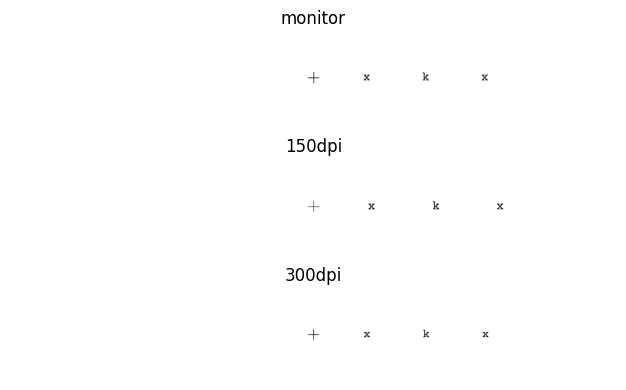

In [5]:
fig, axs = plt.subplots(len(stimuli.RESOLUTIONS), 1, figsize=(12, 4))
for i, resolution in enumerate(stimuli.RESOLUTIONS):
  trial = dict(target="k", ecc_deg=5, gap=8, side="right", inner_flanker="x", outer_flanker="x")
  img   = stimuli.draw_trial(trial, resolution)
  probs = letterProbs(img)
  grid  = makeInputs(img, question)["image_grid_thw"][0].tolist()

  print("%-8s image %d x %d, model sees %d x %d; answer %s (p = %.2f)"
        % (resolution, img.width, img.height, grid[2] * 16, grid[1] * 16, letters[np.argmax(probs)], np.max(probs)))
  axs[i].imshow(img)
  axs[i].set_title(resolution)
  axs[i].axis("off")
plt.tight_layout()
plt.show()

## The run

2,700 trials per resolution and flanker type. The cell saves the results every 500 trials and
skips trials that are already in the file, so if Colab disconnects, run it again and it
continues where it stopped.

Bouma's "x" flankers come first. Set `flankerTypes` to `["x", "random"]` for both.

In [6]:
flankerTypes = ["x"]
resultsFile  = "../data/model_results.csv"

if os.path.exists(resultsFile):
  results = pd.read_csv(resultsFile).to_dict("records")
else:
  results = []
done = set((r["flankers"], r["resolution"], r["index"]) for r in results)


def save():
  pd.DataFrame(results).to_csv(resultsFile, index=False)


startTime = time.time()
for flankers in flankerTypes:
  trials = stimuli.make_trials(flankers)
  for resolution in stimuli.RESOLUTIONS:
    for trial in trials:
      if (flankers, resolution, trial["index"]) in done:
        continue

      probs  = letterProbs(stimuli.draw_trial(trial, resolution))
      answer = letters[np.argmax(probs)]
      hasFlankers = trial["gap"] is not None

      results.append({**trial,
                      "model":             modelName,
                      "resolution":        resolution,
                      "px_per_deg":        stimuli.pixels_per_degree(resolution),
                      "answer":            answer,
                      "correct":           answer == trial["target"],
                      "p_correct":         float(probs[letters.index(trial["target"])]),
                      "answer_is_flanker": hasFlankers and answer in (trial["inner_flanker"], trial["outer_flanker"])})
      if len(results) % 500 == 0:
        save()

    save()
    print("%-6s %-8s done after %.0f s" % (flankers, resolution, time.time() - startTime))

x      monitor  done after 293 s
x      150dpi   done after 717 s
x      300dpi   done after 2845 s


## A first look

Proportion correct per condition. The fits and the comparison with Bouma are done on the
computer from `model_results.csv`.

In [7]:
df = pd.DataFrame(results)
df["gap"] = df["gap"].fillna(-1).astype(int)        # -1 = no flankers
table = df.pivot_table(index=["flankers", "resolution", "ecc_deg"], columns="gap", values="correct")
table = table.rename(columns={-1: "alone"})
table.round(2)

gap                          alone     0     1     2     5     8    11    15
flankers resolution ecc_deg                                                 
x        150dpi     2         0.96  1.00  1.00  1.00  1.00   NaN   NaN   NaN
                    3         0.92  0.98  1.00  1.00  1.00  1.00   NaN   NaN
                    5         0.94  0.96  1.00  1.00  1.00  1.00  1.00  1.00
                    7         0.94  1.00  1.00  1.00  1.00  0.98  1.00  0.98
         300dpi     2         0.88  1.00  0.98  0.92  0.92   NaN   NaN   NaN
                    3         0.90  1.00  1.00  0.92  0.90  0.96   NaN   NaN
                    5         0.86  1.00  0.98  0.96  0.96  0.96  0.96  0.96
                    7         0.90  1.00  0.98  0.94  0.96  0.92  0.96  0.94
         monitor    2         0.96  0.94  1.00  1.00  1.00   NaN   NaN   NaN
                    3         0.96  0.94  1.00  1.00  1.00  1.00   NaN   NaN
                    5         0.94  0.92  1.00  1.00  1.00  1.00  1.00  1.00
                    7         0.94  0.94  1.00  1.00  1.00  1.00  1.00  1.00